In [1]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'svg'
import Funciones as Funciones
from NNMF_GIF import NNMF_GIF 
from pathlib import Path
from ipyfilechooser import FileChooser
import ipywidgets as widgets
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF

In [2]:
FC = FileChooser('Señales AC3E/Femenino')
FC.layout = widgets.Layout(width='1000px')
display(FC)

FileChooser(path='G:\Mi unidad\Facultad\Beca CIN\NNMF-GIF\Señales AC3E\Femenino', filename='', title='', show_…

In [3]:
norma='frobenius'
archivo = Path(FC.selected)
nombre_archivo = archivo.name
datos = np.loadtxt(archivo, delimiter='\t', skiprows=1)
fs_r = 8000

alfa = 0.96
alfa_grid = 0.3
color1 = 'red'
color2 = 'blue'
cmap = Funciones.parula_map
to = 0
tf = 50
tiempos = np.arange(to, tf, 1000/fs_r);


señal_MBK  = datos[:, 0] - np.mean(datos[:, 0])
señal_ACC  = -datos[:, 1]
señal_ACC  = señal_ACC - np.mean(señal_ACC)
if max(abs(señal_ACC)) > 0:
    señal_ACC = señal_ACC / max(abs(señal_ACC)) 

señal_EGG  = datos[:, 3]
señal_dEGG = np.gradient(señal_EGG)
if max(señal_dEGG) > 0:
    señal_dEGG = señal_dEGG / max(señal_dEGG) 

orden = 10 
ripple = 0.1
fc     = 1100

flujo_ovv  = datos[:, 4]
flujo_ovv= Funciones.Detrend(tiempos,flujo_ovv)
flujo_ovv = flujo_ovv+abs(min(flujo_ovv))
flujo_ovv = flujo_ovv/max(abs(flujo_ovv))

SP = CONMF.NNMF_GIF(speech=señal_MBK,
                acelerometro=señal_ACC,
                dEGG = señal_dEGG,
                tiempos=tiempos,
                fs=fs_r,
                norma=norma)

SP1 = NMF.NNMF_GIF(señal=señal_MBK,
                   tiempos=tiempos,
                   fs=fs_r,
                   norma=norma)
SP2 = NMF.NNMF_GIF(señal=señal_ACC,
                   tiempos=tiempos,
                   fs=fs_r,
                   norma=norma)

nmf_flujo1_speech = Funciones.Detrend(SP1.tiempos_gve,SP1.flujo1)
nmf_flujo2_speech = Funciones.Detrend(SP1.tiempos_gve,SP1.flujo2)
nmf_flujo1_speech = nmf_flujo1_speech+abs(min(nmf_flujo1_speech))
nmf_flujo1_speech = nmf_flujo1_speech/max(abs(nmf_flujo1_speech))
nmf_flujo2_speech = nmf_flujo2_speech+abs(min(nmf_flujo2_speech))
nmf_flujo2_speech = nmf_flujo2_speech/max(abs(nmf_flujo2_speech))


nmf_flujo1_acc = Funciones.Detrend(SP2.tiempos_gve,SP2.flujo1)
nmf_flujo2_acc = Funciones.Detrend(SP2.tiempos_gve,SP2.flujo2)
nmf_flujo1_acc = nmf_flujo1_acc+abs(min(nmf_flujo1_acc))
nmf_flujo1_acc = nmf_flujo1_acc/max(abs(nmf_flujo1_acc))
nmf_flujo2_acc = nmf_flujo2_acc+abs(min(nmf_flujo2_acc))
nmf_flujo2_acc = nmf_flujo2_acc/max(abs(nmf_flujo2_acc))


conmf_flujo1_speech = Funciones.Detrend(SP.tiempos_gve,SP.flujo1_speech)
conmf_flujo1_speech = conmf_flujo1_speech+abs(min(conmf_flujo1_speech))
conmf_flujo1_speech = conmf_flujo1_speech/max(abs(conmf_flujo1_speech))

conmf_flujo2_speech = Funciones.Detrend(SP.tiempos_gve,SP.flujo2_speech)
conmf_flujo2_speech = conmf_flujo2_speech+abs(min(conmf_flujo2_speech))
conmf_flujo2_speech = conmf_flujo2_speech/max(abs(conmf_flujo2_speech))



conmf_flujo1_acc = Funciones.Detrend(SP.tiempos_gve,SP.flujo1_acc)
conmf_flujo1_acc = conmf_flujo1_acc+abs(min(conmf_flujo1_acc))
conmf_flujo1_acc = conmf_flujo1_acc/max(abs(conmf_flujo1_acc))

conmf_flujo2_acc = Funciones.Detrend(SP.tiempos_gve,SP.flujo2_acc)
conmf_flujo2_acc = conmf_flujo2_acc+abs(min(conmf_flujo2_acc))
conmf_flujo2_acc = conmf_flujo2_acc/max(abs(conmf_flujo2_acc))



mask = (tiempos >= 5.0) & (tiempos <= 45.0)
flujo_ovv = flujo_ovv[mask]
tiempos = tiempos[mask]

mask = (SP1.tiempos_gve >= 5.0) & (SP1.tiempos_gve <= 45.0)
nmf_flujo1_speech = nmf_flujo1_speech[mask]
nmf_flujo2_speech = nmf_flujo2_speech[mask]
SP1.tiempos_gve = SP1.tiempos_gve[mask]

mask = (SP2.tiempos_gve >= 5.0) & (SP2.tiempos_gve <= 45.0)
nmf_flujo1_acc = nmf_flujo1_acc[mask]
nmf_flujo2_acc = nmf_flujo2_acc[mask]
SP2.tiempos_gve = SP2.tiempos_gve[mask]


mask = (SP.tiempos_gve >= 5.0) & (SP.tiempos_gve <= 45.0)
conmf_flujo1_speech = conmf_flujo1_speech[mask]
conmf_flujo2_speech = conmf_flujo2_speech[mask]
conmf_flujo1_acc = conmf_flujo1_acc[mask]
conmf_flujo2_acc = conmf_flujo2_acc[mask]
SP.tiempos_gve = SP.tiempos_gve[mask]

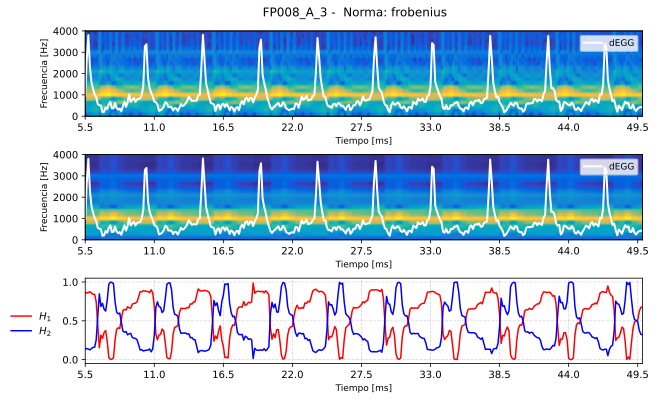

In [ ]:
fig,ax = plt.subplots(3,1,figsize=(10,6))
plt.subplots_adjust(hspace=0.45)
fontsize= 9
linewidth = 2
ax1 = ax[0]
ax1_ = ax1.twinx()
ax2 = ax[1]
ax2_ = ax2.twinx()

ax3 = ax[2]
#for archivo in archivos:
#    for ax_ in axes:
#        ax_.clear()




color2 = 'blue'
color1 = 'red'
color_error = 'green'
loc = 'lower right'
fftseñal,fseñal = Funciones.FFT(señal_MBK,fs_r)


ax1.imshow(SP1.espectrograma,cmap = cmap,origin='lower',aspect='auto',extent=[SP1.to_espec,SP1.tf_espec,SP1.fo_espec,SP1.ff_espec]);
ax1.set_ylabel("Frecuencia [Hz]",fontsize=fontsize);
#ax1.set_title(archivo)
ax1_.plot(SP1.tiempos_espec,señal_dEGG[SP1.long_ventana_espect-1:],color='white',label=r"dEGG",linewidth=2);
ax1_.legend(loc='upper right',fontsize=fontsize);
ax1_.set_xlim(SP1.to_espec,SP1.tf_espec)
ax1_.set_xticks(np.arange(SP1.to_espec,SP1.tf_espec,SP1.duracion_ventana))
ax1_.set_yticks([])
ax1.set_xlabel('Tiempo [ms]',fontsize=fontsize);

ax2.imshow(SP1.espectrograma_aprox,cmap = cmap,origin='lower',aspect='auto',extent=[SP1.to_espec,SP1.tf_espec,SP1.fo_espec,SP1.ff_espec]);
ax2.set_ylabel("Frecuencia [Hz]",fontsize=fontsize);
#ax1.set_title(archivo)

ax2_.plot(SP1.tiempos_espec,señal_dEGG[SP1.long_ventana_espect-1:],color='white',label=r"dEGG",linewidth=2);
ax2_.set_xlim(SP1.to_espec,SP1.tf_espec)
ax2_.set_xticks(np.arange(SP1.to_espec,SP1.tf_espec,SP1.duracion_ventana))
ax2_.legend(loc='upper right',fontsize=fontsize);
ax2_.set_yticks([])
ax2.set_xlabel('Tiempo [ms]',fontsize=fontsize);
# ===============================  Funciones de activación  ==============================================================================================

ax3.plot(SP1.tiempos_espec,SP1.H1,color=color1,label=r'$H_1$')
ax3.plot(SP1.tiempos_espec,SP1.H2,color=color2,label=r'$H_2$')
ax3.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
ax3.set_xlim(SP1.to_espec,SP1.tf_espec)
ax3.set_xticks(np.arange(SP1.to_espec,SP1.tf_espec,SP1.duracion_ventana))
ax3.set_xlabel('Tiempo [ms]',fontsize=fontsize);
handles = [
    plt.Line2D([0], [0], color=color1, label=r'$H_1$'),
    plt.Line2D([0], [0], color=color2, label=r'$H_2$'),
]
titulo = nombre_archivo.split(".txt")[0] + " -  Norma: " + norma 

fig.suptitle(titulo,
             fontsize=12,
             x=0.50,y=0.935)


fig.legend(handles=handles,
           loc='upper center',
           bbox_to_anchor=(0.05, 0.25),  # ← misma altura, más a la derecha
           frameon=False);

#fig.suptitle(
#f"{archivo} | norma: {norma} ",
#fontsize=8,
#y=0.91
#);
fig.savefig("NMF_espectrograma_"+nombre_archivo+".pdf",bbox_inches = 'tight');
#fig.savefig("Prueba Repositorio II/Presentacion/Itakura-saito/"+archivo+'.pdf',bbox_inches = 'tight');

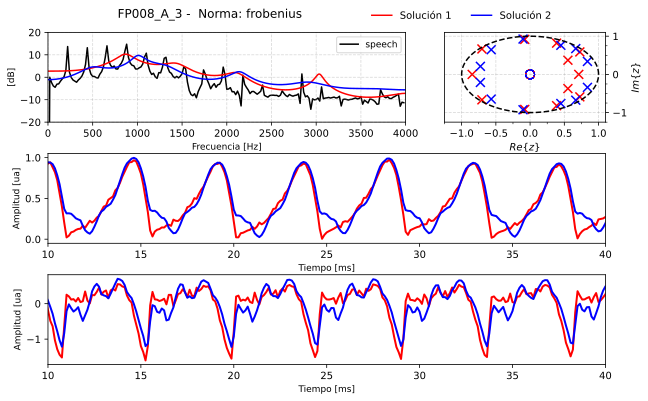

In [8]:
fig = plt.figure(figsize=(10,6))
fontsize= 9
color_speech = 'k'
widths  = [1,0.45]
heights = [1,1,1]
gs  = fig.add_gridspec(3, 2,width_ratios=widths,height_ratios=heights,wspace=0.15,hspace=0.35)


ax4 = fig.add_subplot(gs[0,0])
ax5 = fig.add_subplot(gs[0,1])
ax6 = fig.add_subplot(gs[1,:])
ax7 = fig.add_subplot(gs[2,:])

fw1,hw1 = sig.freqz([1],SP1.a_W1,fs=fs_r)
fw2,hw2 = sig.freqz([1],SP1.a_W2,fs=fs_r)
# ===============================  Respuesta en frecuencia de W1 y W2 ==============================================================================================

ax4.plot(fw1,10*np.log10(np.abs(hw1)),color=color1)
ax4.plot(fw2,10*np.log10(np.abs(hw2)),color=color2)
ax4.plot(fseñal,10*np.log10(np.abs(fftseñal)),label='speech',color=color_speech,zorder=-1)
ax4.set_xlim(0,fs_r/2);
#ax4.set_xticks(np.arange(0,fs_r/2,100))
ax4.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
ax4.set_xlabel('Frecuencia [Hz]',fontsize=fontsize);
ax4.set_ylabel('[dB]',fontsize=fontsize);
ax4.set_ylim([-20,20])
ax4.legend(loc='upper right',fontsize=fontsize);

# ===============================  Polos y ceros ==============================================================================================

theta = np.linspace(0, 2*np.pi, 200)

ax5.plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
ax5.yaxis.tick_right()
ax5.yaxis.set_label_position("right")
# Graficar ceros (O) y polos (X)
ax5.scatter(np.real(SP1.ceros_W1), np.imag(SP1.ceros_W1), s=80, facecolors='none', edgecolors=color1, label='Ceros')
ax5.scatter(np.real(SP1.polos_W1), np.imag(SP1.polos_W1), s=80, marker='x', color=color1, label='Polos')

# Graficar ceros (O) y polos (X)
ax5.scatter(np.real(SP1.ceros_W2), np.imag(SP1.ceros_W2), s=80,linestyle='dashed', facecolors='none', edgecolors=color2, label='Ceros')
ax5.scatter(np.real(SP1.polos_W2), np.imag(SP1.polos_W2), s=80, marker='x', color=color2, label='Polos')
ax5.set_xticks(np.arange(-1.25,1.25,0.25),minor=True)
ax5.set_yticks(np.arange(-1.25,1.25,0.25),minor=True)

ax5.set_ylabel(r"$Im\{z\}$")
#ax5_.set_ylim([-1.75,1.75])
ax5.set_xlabel(r"$Re\{z\}$")
ax5.grid(True,linestyle='dashed',color='gray',alpha=0.3)

# ===============================  Flujos glóticos ==============================================================================================
#ax6.plot(tiempos,flujo_ovv,color='k',alpha=0.7,label=r'$u_g(t)$');
ax6.plot(SP1.tiempos_gve,Funciones.Sincronizar(nmf_flujo1_speech,flujo_ovv),color=color1,linewidth = 2);
ax6.plot(SP1.tiempos_gve,Funciones.Sincronizar(nmf_flujo2_speech,flujo_ovv),color=color2,linewidth = 2);
#ax6.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
#ax7.set_xlabel('Tiempo [ms]');
ax6.set_xlabel('Tiempo [ms]',fontsize=fontsize);
ax6.set_xlim([10,40])
ax6.set_ylabel("Amplitud [ua]",fontsize=fontsize)

#ax7.plot(tiempos,np.gradient(flujo_ovv,tiempos),alpha=0.7,color='k');
ax7.plot(SP1.tiempos_gve,np.gradient(nmf_flujo1_speech,tiempos),color=color1,linewidth = 2);
ax7.plot(SP1.tiempos_gve,np.gradient(nmf_flujo2_speech,tiempos),color=color2,linewidth = 2);
#ax7.grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
#ax7.set_xlabel('Tiempo [ms]');
ax7.set_xlabel('Tiempo [ms]',fontsize=fontsize);
ax7.set_xlim([10,40])
ax7.set_ylabel("Amplitud [ua]",fontsize=fontsize)


handles = [
    #plt.Line2D([0], [0], color='k', alpha=0.7, label='OVV'),
    plt.Line2D([0], [0], color=color1, label='Solución 1'),
    plt.Line2D([0], [0], color=color2, label='Solución 2'),
]
titulo = nombre_archivo.split(".txt")[0] + " -  Norma: " + norma 

fig.suptitle(titulo,
             fontsize=12,
             x=0.35,y=0.935)

fig.legend(handles=handles,
           loc='upper center',
           bbox_to_anchor=(0.7, 0.95),  # ← misma altura, más a la derecha
           ncol=3,
           frameon=False);

fig.savefig("NMF_solucion_"+nombre_archivo+".pdf",bbox_inches = 'tight');